<a href="https://colab.research.google.com/github/hohohoo07/Advanced_software_Lab./blob/main/AS_Week13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip -q install ultralytics==8.3.241

In [2]:
import torch, ultralytics, cv2

print("ultralytics:", ultralytics.__version__)
print("torch:", torch.__version__)

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
ultralytics: 8.3.241
torch: 2.14.1+cpu
device: cpu


In [3]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print(model.task)
print(model.names[0])

detect
person


In [4]:
from pathlib import Path
import urllib.request

DATA = Path("/content/week13_yolo/data")
DATA.mkdir(parents=True, exist_ok=True)

urls = {
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg": "https://ultralytics.com/images/zidane.jpg"
}

for filename, url in urls.items():
    urllib.request.urlretrieve(url, DATA / filename)
    print(f"{filename} 다운로드 완료!")

bus.jpg 다운로드 완료!
zidane.jpg 다운로드 완료!


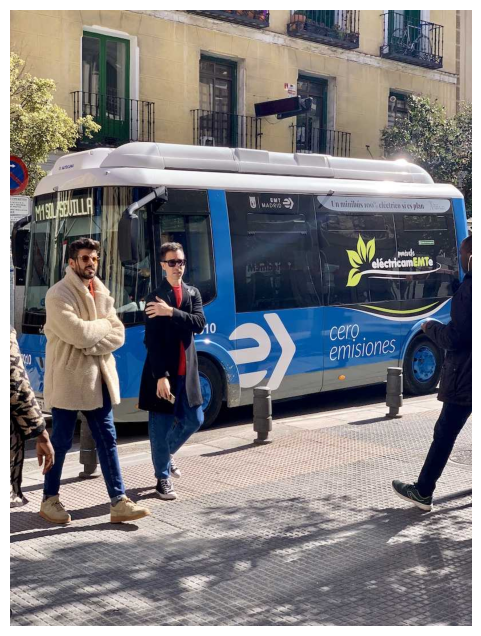

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

# 버스 이미지 불러오기
img = Image.open(DATA / "bus.jpg")

# 이미지 출력
plt.figure(figsize=(6, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

In [6]:
results = model.predict(
    source=str(DATA / "bus.jpg"),
    conf=0.25,
    iou=0.45,
    imgsz=640,
    device=DEVICE,
    verbose=False
)

r = results[0]

print("boxes:", len(r.boxes))

boxes: 5


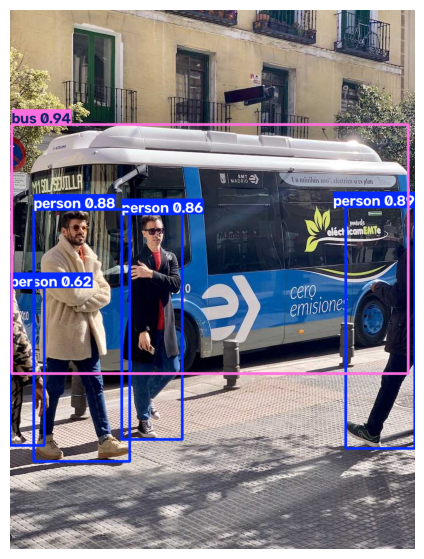

In [7]:
import matplotlib.pyplot as plt

annotated_bgr = r.plot()

plt.figure(figsize=(9, 7))
plt.imshow(cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [8]:
xyxy = r.boxes.xyxy.cpu().numpy()
scores = r.boxes.conf.cpu().numpy()
class_ids = r.boxes.cls.cpu().numpy().astype(int)

for box, score, cid in zip(xyxy, scores, class_ids):
    print(
        r.names[cid],
        round(float(score), 3),
        box.round(1).tolist()
    )


bus 0.94 [3.799999952316284, 229.39999389648438, 796.2000122070312, 728.4000244140625]
person 0.888 [671.0, 394.79998779296875, 809.7999877929688, 878.7000122070312]
person 0.878 [47.400001525878906, 399.6000061035156, 239.3000030517578, 904.2000122070312]
person 0.856 [223.10000610351562, 408.70001220703125, 344.5, 860.4000244140625]
person 0.622 [0.0, 556.0999755859375, 68.9000015258789, 872.4000244140625]


In [9]:
from collections import Counter

counts = Counter(r.names[cid] for cid in class_ids)

print(counts)
print("person:", counts["person"])

Counter({'person': 4, 'bus': 1})
person: 4


In [10]:
# person 클래스 번호 찾기
person_id = next(
    k for k, v in model.names.items()
    if v == "person"
)

# 사람만 탐지
people = model.predict(
    str(DATA / "bus.jpg"),
    classes=[person_id],
    conf=0.25,
    iou=0.45,
    device=DEVICE,
    verbose=False
)[0]

print("person boxes:", len(people.boxes))

person boxes: 4


In [11]:
for c in [0.10, 0.25, 0.50, 0.75]:
    out = model.predict(
        str(DATA / "bus.jpg"),
        conf=c,
        iou=0.45,
        classes=None,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )[0]

    print(c, len(out.boxes))

0.1 6
0.25 5
0.5 5
0.75 4


In [12]:
for t in [0.30, 0.50, 0.70]:
    out = model.predict(
        str(DATA / "bus.jpg"),
        conf=0.25,
        iou=t,
        imgsz=640,
        device=DEVICE,
        verbose=False
    )[0]

    print(t, len(out.boxes))

0.3 5
0.5 5
0.7 5


In [13]:
for size in [320, 640]:
    out = model.predict(
        str(DATA / "bus.jpg"),
        imgsz=size,
        conf=0.25,
        iou=0.45,
        device=DEVICE,
        verbose=False
    )[0]

    print(size, len(out.boxes), out.speed)

320 5 {'preprocess': 2.3465859999305394, 'inference': 72.8775880000967, 'postprocess': 0.9806560000242825}
640 5 {'preprocess': 3.9608060000091427, 'inference': 282.6101489999928, 'postprocess': 2.1113499999501073}


In [14]:
# 원본 이미지 크기 확인
if len(r.boxes):
    h, w = r.orig_img.shape[:2]

    # 첫 번째 탐지 객체의 좌표 가져오기
    x1, y1, x2, y2 = r.boxes.xyxy[0].cpu().numpy()

    # 좌표를 정수로 변환하고 이미지 범위 안으로 제한
    x1, x2 = max(0, int(x1)), min(w, int(x2))
    y1, y2 = max(0, int(y1)), min(h, int(y2))

    # 객체 영역 자르기
    crop = r.orig_img[y1:y2, x1:x2]

    # 이미지 저장
    if crop.size:
        cv2.imwrite(str(DATA / "crop_01.jpg"), crop)
        print("객체 이미지 저장 완료!")

객체 이미지 저장 완료!


In [15]:
import pandas as pd

# 탐지 결과를 표 형태로 정리
rows = [
    [r.names[c], float(s), *b.tolist()]
    for b, s, c in zip(xyxy, scores, class_ids)
]

# DataFrame 생성
df = pd.DataFrame(
    rows,
    columns=["class", "confidence", "x1", "y1", "x2", "y2"]
)

# CSV 파일 저장
OUT = Path("/content/week13_yolo/output")
OUT.mkdir(parents=True, exist_ok=True)

df.to_csv(
    OUT / "detections.csv",
    index=False,
    encoding="utf-8-sig"
)

# 탐지 결과 이미지 저장
cv2.imwrite(
    str(OUT / "bus_detected.jpg"),
    r.plot()
)

print("저장 완료!")
display(df)

저장 완료!


,class,confidence,x1,y1,x2,y2
0,bus,0.940152,3.832718,229.364197,796.194580,728.412231
1,person,0.888220,671.017212,394.833160,809.809753,878.712463
2,person,0.878255,47.404728,399.565155,239.300690,904.195007
3,person,0.855772,223.058945,408.688568,344.467682,860.435730
4,person,0.621919,0.021726,556.068420,68.885460,872.359192


탐지된 객체 수: 3


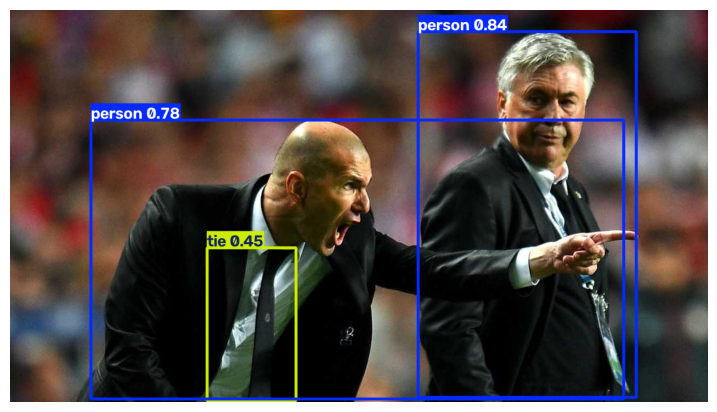

In [16]:
# 두 번째 이미지 객체 탐지
zidane_result = model.predict(
    source=str(DATA / "zidane.jpg"),
    conf=0.25,
    iou=0.45,
    imgsz=640,
    device=DEVICE,
    verbose=False
)[0]

# 탐지된 객체 개수 출력
print("탐지된 객체 수:", len(zidane_result.boxes))

# 탐지 결과 시각화
plt.figure(figsize=(9, 6))
plt.imshow(
    cv2.cvtColor(
        zidane_result.plot(),
        cv2.COLOR_BGR2RGB
    )
)
plt.axis("off")
plt.show()

In [17]:
import cv2

video_path = DATA / "sample_video.mp4"

fps = 8
width, height = 640, 480

writer = cv2.VideoWriter(
    str(video_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

for filename in ["bus.jpg", "zidane.jpg"]:
    img = cv2.imread(str(DATA / filename))
    img = cv2.resize(img, (width, height))

    for _ in range(8):
        writer.write(img)

writer.release()

print("영상 생성 완료:", video_path)

영상 생성 완료: /content/week13_yolo/data/sample_video.mp4


In [18]:
stream = model.predict(
    source=str(DATA / "sample_video.mp4"),
    stream=True,
    conf=0.25,
    iou=0.45,
    imgsz=640,
    device=DEVICE,
    verbose=False
)

for frame_no, result in enumerate(stream):
    print(frame_no, len(result.boxes))

0 5
1 5
2 5
3 5
4 5
5 5
6 5
7 5
8 3
9 3
10 3
11 3
12 3
13 3
14 3
15 3


In [19]:
# 입력 영상 정보 확인
video_path = DATA / "sample_video.mp4"

cap = cv2.VideoCapture(str(video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

cap.release()

# 결과 동영상 저장
output_path = OUT / "video_detected.mp4"

writer = cv2.VideoWriter(
    str(output_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (w, h)
)

try:
    for result in model.predict(
        source=str(video_path),
        stream=True,
        conf=0.25,
        iou=0.45,
        imgsz=640,
        device=DEVICE,
        verbose=False
    ):
        writer.write(result.plot())

finally:
    writer.release()

print("동영상 저장 완료!")
print("저장 경로:", output_path)

동영상 저장 완료!
저장 경로: /content/week13_yolo/output/video_detected.mp4


In [20]:
from IPython.display import Video, display

display(Video(
    str(output_path),
    embed=True
))

In [21]:
import time
import torch

# GPU 사용 시 연산 완료까지 기다리는 함수
def sync_device():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# 입력 크기별 실행 시간 측정
for size in [320, 640]:
    times = []

    # 준비 실행 (워밍업)
    model.predict(
        str(DATA / "bus.jpg"),
        imgsz=size,
        device=DEVICE,
        verbose=False
    )

    # 5회 반복 측정
    for _ in range(5):
        sync_device()
        start = time.perf_counter()

        model.predict(
            str(DATA / "bus.jpg"),
            imgsz=size,
            device=DEVICE,
            verbose=False
        )

        sync_device()
        elapsed = time.perf_counter() - start
        times.append(elapsed)

    avg = sum(times) / len(times)

    print(f"imgsz={size}")
    print(f"평균 실행 시간: {avg:.4f}초")
    print(f"평균 FPS: {1/avg:.2f}")
    print()

imgsz=320
평균 실행 시간: 0.1170초
평균 FPS: 8.55

imgsz=640
평균 실행 시간: 0.4076초
평균 FPS: 2.45

